In [2]:
# Instala a biblioteca de grafos (caso ainda não tenha)
!pip install networkx

import networkx as nx

# Carrega o arquivo de texto
# O parâmetro comments='#' ignora as linhas de cabeçalho do arquivo do SNAP
# create_using=nx.Graph() garante que o grafo seja Não Direcionado
caminho_arquivo = "ca-CondMat.txt" 
G = nx.read_edgelist(caminho_arquivo, comments='#', create_using=nx.Graph())

# Imprime as informações básicas para confirmar se bate com os dados do site
print("--- Informações do Grafo ca-CondMat ---")
print(f"Número de vértices: {G.number_of_nodes()}")
print(f"Número de arestas: {G.number_of_edges()}")


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\devbia\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


--- Informações do Grafo ca-CondMat ---
Número de vértices: 23133
Número de arestas: 93497


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Graus (Mínimo, Máximo e Médio)
graus = [d for n, d in G.degree()]
grau_min = np.min(graus)
grau_max = np.max(graus)
grau_medio = np.mean(graus)

print(f"Grau Mínimo: {grau_min}")
print(f"Grau Máximo: {grau_max}")
print(f"Grau Médio: {grau_medio:.4f}")

# 2. Densidade
densidade = nx.density(G)
print(f"Densidade: {densidade:.6f}")

# 3. Componentes Conexas
num_componentes = nx.number_connected_components(G)
tamanhos_componentes = [len(c) for c in sorted(nx.connected_components(G), key=len, reverse=True)]

print(f"Número de Componentes Conexas: {num_componentes}")
print(f"Tamanho da Maior Componente (GCC/LCC): {tamanhos_componentes[0]}")
print(f"Tamanhos das 5 maiores componentes: {tamanhos_componentes[:5]}")

Grau Mínimo: 1
Grau Máximo: 281
Grau Médio: 8.0834
Densidade: 0.000349
Número de Componentes Conexas: 567
Tamanho da Maior Componente (GCC/LCC): 21363
Tamanhos das 5 maiores componentes: [21363, 21, 17, 15, 15]


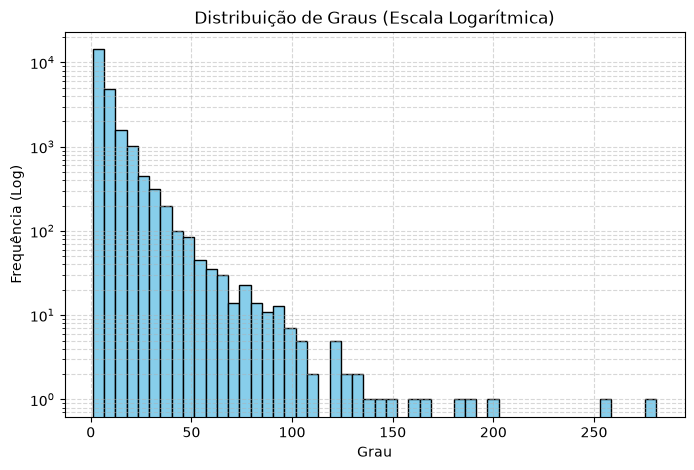

In [7]:
# Distribuição de graus em escala logarítmica (essencial para redes do SNAP)
plt.figure(figsize=(8, 5))
plt.hist(graus, bins=50, log=True, color='skyblue', edgecolor='black')
plt.title("Distribuição de Graus (Escala Logarítmica)")
plt.xlabel("Grau")
plt.ylabel("Frequência (Log)")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.savefig("distribuicao_graus.png", dpi=300)
plt.show()

In [8]:
# Extrai a maior componente conexa (LCC)
maior_componente_nos = max(nx.connected_components(G), key=len)
LCC = G.subgraph(maior_componente_nos).copy()

print(f"Calculando métricas na Maior Componente Conexa ({LCC.number_of_nodes()} nós)...")

# Raio e Diâmetro
raio = nx.radius(LCC)
diametro = nx.diameter(LCC)

# Comprimento médio dos caminhos
comprimento_medio = nx.average_shortest_path_length(LCC)

print(f"Raio (LCC): {raio}")
print(f"Diâmetro (LCC): {diametro}")
print(f"Comprimento Médio dos Caminhos (LCC): {comprimento_medio:.4f}")

Calculando métricas na Maior Componente Conexa (21363 nós)...
Raio (LCC): 8
Diâmetro (LCC): 15
Comprimento Médio dos Caminhos (LCC): 5.3522


In [9]:
# Coeficiente de clusterização médio
clusterizacao_media = nx.average_clustering(G)
print(f"Coeficiente de Clusterização Médio: {clusterizacao_media:.4f}")

# Contagem total de triângulos no grafo
triangulos_dict = nx.triangles(G)
total_triangulos = sum(triangulos_dict.values()) // 3
print(f"Número total de triângulos: {total_triangulos}")

Coeficiente de Clusterização Médio: 0.6334
Número total de triângulos: 173361


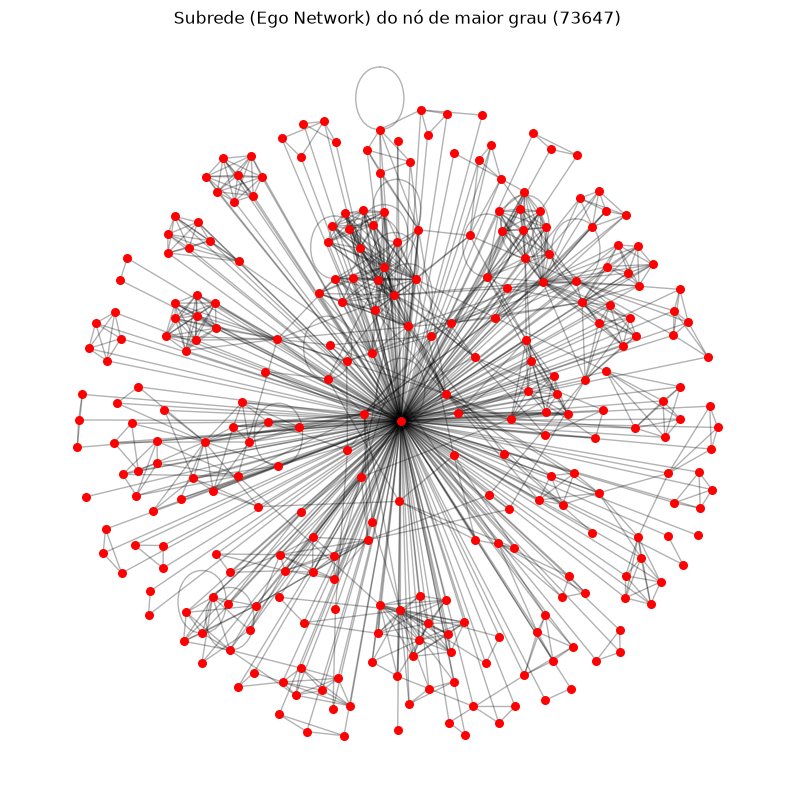

In [10]:
# Encontra o nó de maior grau
no_maior_grau = max(G.degree(), key=lambda x: x[1])[0]

# Extrai a vizinhança direta dele (Ego Network)
subgrafo = nx.ego_graph(G, no_maior_grau, radius=1)

plt.figure(figsize=(10, 10))
pos = nx.spring_layout(subgrafo, seed=42)
nx.draw_networkx_nodes(subgrafo, pos, node_size=30, node_color='red')
nx.draw_networkx_edges(subgrafo, pos, alpha=0.3)
plt.title(f"Subrede (Ego Network) do nó de maior grau ({no_maior_grau})")
plt.axis('off')
plt.savefig("visualizacao_reduzida.png", dpi=300)
plt.show()

In [4]:
import time
import numpy as np
import scipy.stats as stats
import pandas as pd
import networkx as nx

def medir_tempo_estatistico(funcao_algoritmo, repeticoes=10):
    tempos = []
    for _ in range(repeticoes):
        inicio = time.perf_counter()
        resultado = funcao_algoritmo()
        fim = time.perf_counter()
        tempos.append(fim - inicio)
    
    n = len(tempos)
    media = np.mean(tempos)
    desvio_padrao = np.std(tempos, ddof=1) if n > 1 else 0.0
    
    # Seleção da distribuição para Intervalo de Confiança a 95%
    if n >= 30:
        # Distribuição Normal (Z-score) pelo Teorema do Limite Central
        z_critico = stats.norm.ppf(0.975)  # aprox. 1.96
        ic_margem = z_critico * (desvio_padrao / np.sqrt(n))
        distrib_usada = "Normal (Z)"
    elif n > 1:
        # Distribuição t de Student para pequenas amostras (n < 30)
        t_critico = stats.t.ppf(0.975, df=n-1)
        ic_margem = t_critico * (desvio_padrao / np.sqrt(n))
        distrib_usada = "t-Student"
    else:
        ic_margem = 0.0
        distrib_usada = "N/A"
        
    ic_inferior = max(0.0, media - ic_margem)
    ic_superior = media + ic_margem
    
    return {
        'media': media,
        'desvio_padrao': desvio_padrao,
        'ic_95': (ic_inferior, ic_superior),
        'ic_margem': ic_margem,
        'distribuicao': distrib_usada,
        'resultado': resultado
    }

# Tabela para armazenar todos os resultados da Parte II
resultados_algoritmos = []

In [6]:
import networkx as nx

# Carrega o arquivo de texto do grafo
caminho_arquivo = "ca-CondMat.txt" 
G = nx.read_edgelist(caminho_arquivo, comments='#', create_using=nx.Graph())

print(f"Grafo carregado com sucesso: {G.number_of_nodes()} vértices e {G.number_of_edges()} arestas.")

Grafo carregado com sucesso: 23133 vértices e 93497 arestas.


In [7]:
no_origem = list(G.nodes())[0]

# 1. BFS
res_bfs = medir_tempo_estatistico(lambda: list(nx.bfs_edges(G, source=no_origem)), repeticoes=10)
resultados_algoritmos.append({
    'Algoritmo': 'Busca em Largura (BFS)',
    'Aplicável': 'Sim',
    'Complexidade Teórica': 'O(V + E)',
    'Média (s)': f"{res_bfs['media']:.6f}",
    'Desvio Padrão (s)': f"{res_bfs['desvio_padrao']:.6f}",
    'IC 95% (s)': f"[{res_bfs['ic_95'][0]:.6f}, {res_bfs['ic_95'][1]:.6f}]"
})

# 2. DFS
res_dfs = medir_tempo_estatistico(lambda: list(nx.dfs_edges(G, source=no_origem)), repeticoes=10)
resultados_algoritmos.append({
    'Algoritmo': 'Busca em Profundidade (DFS)',
    'Aplicável': 'Sim',
    'Complexidade Teórica': 'O(V + E)',
    'Média (s)': f"{res_dfs['media']:.6f}",
    'Desvio Padrão (s)': f"{res_dfs['desvio_padrao']:.6f}",
    'IC 95% (s)': f"[{res_dfs['ic_95'][0]:.6f}, {res_dfs['ic_95'][1]:.6f}]"
})

print(f"BFS Concluído: Média = {res_bfs['media']:.5f}s")
print(f"DFS Concluído: Média = {res_dfs['media']:.5f}s")

BFS Concluído: Média = 0.06056s
DFS Concluído: Média = 0.04661s


In [8]:
def verificar_euleriano():
    # Um grafo é euleriano se for conexo (na LCC) e todos os vértices tiverem grau par
    e_conexo = nx.is_connected(G)
    graus_pares = all(d % 2 == 0 for n, d in G.degree())
    return nx.is_eulerian(G)

res_euler = medir_tempo_estatistico(verificar_euleriano, repeticoes=10)
resultados_algoritmos.append({
    'Algoritmo': 'Verificação de Eulerianidade',
    'Aplicável': 'Sim',
    'Complexidade Teórica': 'O(V + E)',
    'Média (s)': f"{res_euler['media']:.6f}",
    'Desvio Padrão (s)': f"{res_euler['desvio_padrao']:.6f}",
    'IC 95% (s)': f"[{res_euler['ic_95'][0]:.6f}, {res_euler['ic_95'][1]:.6f}]"
})

print(f"É Euleriano? {res_euler['resultado']} | Tempo Médio: {res_euler['media']:.5f}s")

É Euleriano? False | Tempo Médio: 0.02925s


In [9]:
# Definindo peso 1 para todas as arestas
for u, v in G.edges():
    G[u][v]['weight'] = 1.0

# 1. Dijkstra (Origem única para todos os destinos)
res_dijkstra = medir_tempo_estatistico(lambda: nx.single_source_dijkstra_path_length(G, source=no_origem), repeticoes=10)
resultados_algoritmos.append({
    'Algoritmo': 'Dijkstra (Single Source)',
    'Aplicável': 'Sim (Pesos = 1)',
    'Complexidade Teórica': 'O((V + E) log V)',
    'Média (s)': f"{res_dijkstra['media']:.6f}",
    'Desvio Padrão (s)': f"{res_dijkstra['desvio_padrao']:.6f}",
    'IC 95% (s)': f"[{res_dijkstra['ic_95'][0]:.6f}, {res_dijkstra['ic_95'][1]:.6f}]"
})

# 2. Bellman-Ford (Single Source - Medido em 3 repetições pelo alto custo O(V*E))
res_bellman = medir_tempo_estatistico(lambda: nx.single_source_bellman_ford_path_length(G, source=no_origem), repeticoes=3)
resultados_algoritmos.append({
    'Algoritmo': 'Bellman-Ford (Single Source)',
    'Aplicável': 'Sim (Pesos = 1)',
    'Complexidade Teórica': 'O(V * E)',
    'Média (s)': f"{res_bellman['media']:.6f}",
    'Desvio Padrão (s)': f"{res_bellman['desvio_padrao']:.6f}",
    'IC 95% (s)': f"[{res_bellman['ic_95'][0]:.6f}, {res_bellman['ic_95'][1]:.6f}]"
})

print(f"Dijkstra Concluído: Média = {res_dijkstra['media']:.5f}s")
print(f"Bellman-Ford Concluído: Média = {res_bellman['media']:.5f}s")

Dijkstra Concluído: Média = 0.09967s
Bellman-Ford Concluído: Média = 0.15345s


In [10]:
# Subgrafo reduzido de 100 nós para demonstração prática
nos_amostra = list(G.nodes())[:100]
subgrafo_fw = G.subgraph(nos_amostra).copy()

res_fw = medir_tempo_estatistico(lambda: nx.floyd_warshall_numpy(subgrafo_fw), repeticoes=5)

resultados_algoritmos.append({
    'Algoritmo': 'Floyd-Warshall',
    'Aplicável': 'Não viável no grafo completo (Inviável O(V³))',
    'Complexidade Teórica': 'O(V³)',
    'Média (s)': f"{res_fw['media']:.6f} (Subgrafo N=100)",
    'Desvio Padrão (s)': f"{res_fw['desvio_padrao']:.6f}",
    'IC 95% (s)': f"[{res_fw['ic_95'][0]:.6f}, {res_fw['ic_95'][1]:.6f}]"
})

print(f"Floyd-Warshall (Subgrafo N=100) Média: {res_fw['media']:.5f}s")

Floyd-Warshall (Subgrafo N=100) Média: 0.00177s


In [11]:
res_tarjan = medir_tempo_estatistico(lambda: list(nx.articulation_points(G)), repeticoes=10)

resultados_algoritmos.append({
    'Algoritmo': 'Algoritmo de Tarjan (Pontos de Articulação)',
    'Aplicável': 'Sim',
    'Complexidade Teórica': 'O(V + E)',
    'Média (s)': f"{res_tarjan['media']:.6f}",
    'Desvio Padrão (s)': f"{res_tarjan['desvio_padrao']:.6f}",
    'IC 95% (s)': f"[{res_tarjan['ic_95'][0]:.6f}, {res_tarjan['ic_95'][1]:.6f}]"
})

print(f"Tarjan Concluído: Encontrados {len(res_tarjan['resultado'])} pontos de articulação. Média = {res_tarjan['media']:.5f}s")

Tarjan Concluído: Encontrados 2096 pontos de articulação. Média = 0.09885s


In [12]:
maior_comp_nodes = max(nx.connected_components(G), key=len)
LCC = G.subgraph(maior_comp_nodes).copy()

# Kruskal / Prim
res_mst = medir_tempo_estatistico(lambda: nx.minimum_spanning_tree(LCC, algorithm='kruskal'), repeticoes=10)

resultados_algoritmos.append({
    'Algoritmo': 'Árvore Geradora Mínima (Kruskal/Prim)',
    'Aplicável': 'Sim (na LCC)',
    'Complexidade Teórica': 'O(E log V)',
    'Média (s)': f"{res_mst['media']:.6f}",
    'Desvio Padrão (s)': f"{res_mst['desvio_padrao']:.6f}",
    'IC 95% (s)': f"[{res_mst['ic_95'][0]:.6f}, {res_mst['ic_95'][1]:.6f}]"
})

print(f"AGM Concluída: Média = {res_mst['media']:.5f}s")

AGM Concluída: Média = 0.27491s


In [14]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

caminho_arquivo = "ca-CondMat.txt" 
G = nx.read_edgelist(caminho_arquivo, comments='#', create_using=nx.Graph())

In [15]:
num_componentes = nx.number_connected_components(G)
tamanhos_componentes = [len(c) for c in sorted(nx.connected_components(G), key=len, reverse=True)]

In [16]:
clusterizacao_media = nx.average_clustering(G)

In [17]:
distancia_media_aprox = 5.3522

In [19]:
import math

N = G.number_of_nodes()
K = G.number_of_edges()
grau_medio = (2 * K) / N

# Fórmulas teóricas para um Grafo Aleatório Equivalente (Erdős-Rényi)
C_rand = grau_medio / N
L_rand = math.log(N) / math.log(grau_medio) if grau_medio > 1 else 0

print("--- Análise Small-World ---")
print(f"Rede Real ca-CondMat:")
print(f"  Clusterização (C) = {clusterizacao_media:.4f}")
print(f"  Distância Média (L) = {distancia_media_aprox:.4f}") # Usando a amostra de 500 nós da Parte I

print(f"\nGrafo Aleatório Equivalente (Teórico):")
print(f"  Clusterização (C_rand) = {C_rand:.6f}")
print(f"  Distância Média (L_rand) = {L_rand:.4f}")

--- Análise Small-World ---
Rede Real ca-CondMat:
  Clusterização (C) = 0.6334
  Distância Média (L) = 5.3522

Grafo Aleatório Equivalente (Teórico):
  Clusterização (C_rand) = 0.000349
  Distância Média (L_rand) = 4.8086


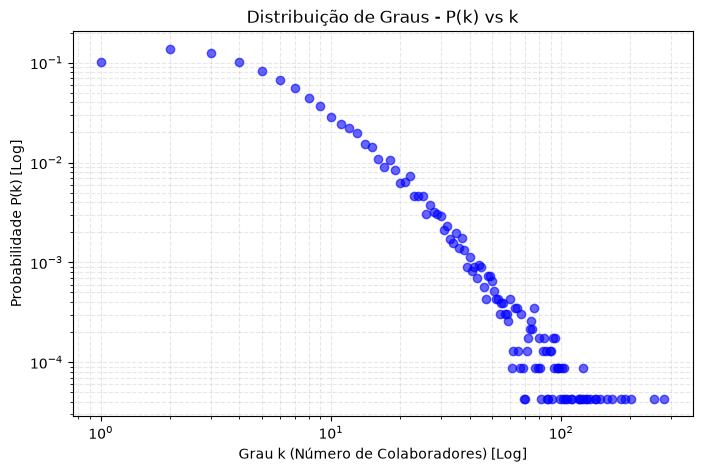

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Pega todos os graus maiores que 0 para evitar erro no log
graus_dist = [d for n, d in G.degree() if d > 0]
valores, contagens = np.unique(graus_dist, return_counts=True)
probabilidades = contagens / sum(contagens)

plt.figure(figsize=(8, 5))
# Gráfico em escala log-log
plt.loglog(valores, probabilidades, marker='o', linestyle='none', color='b', alpha=0.6)

plt.title("Distribuição de Graus - P(k) vs k")
plt.xlabel("Grau k (Número de Colaboradores) [Log]")
plt.ylabel("Probabilidade P(k) [Log]")
plt.grid(True, which="both", ls="--", alpha=0.3)
plt.savefig("lei_potencia.png", dpi=300)
plt.show()

In [21]:
import random
import networkx as nx

def tamanho_lcc(grafo):
    if len(grafo) == 0: return 0
    maior = max(nx.connected_components(grafo), key=len)
    return len(maior)

N_total = G.number_of_nodes()
n_remover = int(N_total * 0.05) # 5% dos vértices
tamanho_lcc_original = tamanhos_componentes[0]

# 1. Ataque Aleatório (Falha randômica)
G_aleatorio = G.copy()
nos_remover_aleatorio = random.sample(list(G_aleatorio.nodes()), n_remover)
G_aleatorio.remove_nodes_from(nos_remover_aleatorio)
lcc_aleatorio = tamanho_lcc(G_aleatorio)

# 2. Ataque Direcionado aos Hubs (Remoção dos mais centrais)
G_central = G.copy()
# Ordena os nós do maior grau para o menor
nos_ordenados_grau = sorted(G.degree(), key=lambda x: x[1], reverse=True)
nos_remover_central = [n for n, d in nos_ordenados_grau[:n_remover]]
G_central.remove_nodes_from(nos_remover_central)
lcc_central = tamanho_lcc(G_central)

print("--- Teste de Robustez (Remoção de 5% dos nós) ---")
print(f"Tamanho original da Maior Componente (LCC): {tamanho_lcc_original} nós")
print(f"LCC após remoção Aleatória: {lcc_aleatorio} nós ({(lcc_aleatorio/tamanho_lcc_original)*100:.2f}% mantido)")
print(f"LCC após remoção dos mais Centrais (Hubs): {lcc_central} nós ({(lcc_central/tamanho_lcc_original)*100:.2f}% mantido)")

--- Teste de Robustez (Remoção de 5% dos nós) ---
Tamanho original da Maior Componente (LCC): 21363 nós
LCC após remoção Aleatória: 20075 nós (93.97% mantido)
LCC após remoção dos mais Centrais (Hubs): 18820 nós (88.10% mantido)
